# Tip Prediction — Seaborn `tips` Dataset

244 rows. The seaborn-built-in restaurant tips dataset. I picked this because it's small enough that I could actually look at every variable individually and not feel bad about it.

Question: how well can total bill, time of day, day of week, and party size predict the tip amount?


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(2)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)

df = sns.load_dataset("tips")
print(df.shape, df.columns.tolist())
df.head()


(244, 7) ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## quick look — is tip really just a % of total bill?

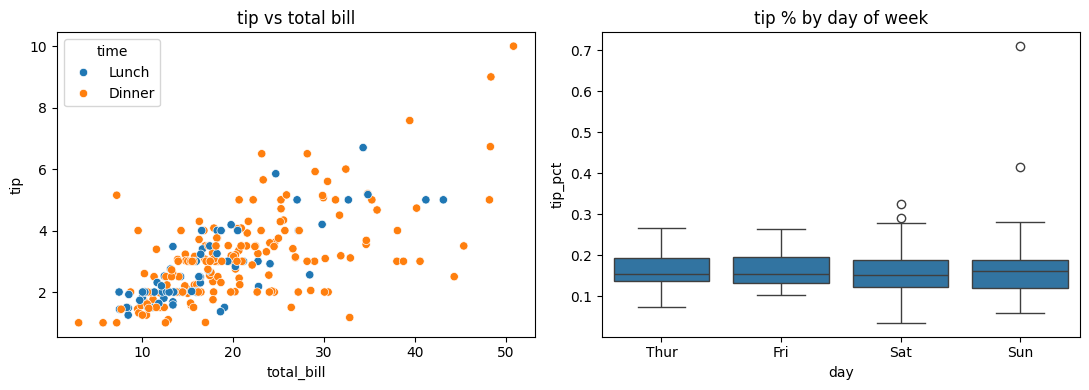

avg tip %: 0.161


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df, x="total_bill", y="tip", hue="time", ax=ax[0])
ax[0].set_title("tip vs total bill")
df["tip_pct"] = df["tip"] / df["total_bill"]
sns.boxplot(data=df, x="day", y="tip_pct", ax=ax[1])
ax[1].set_title("tip % by day of week")
plt.tight_layout(); plt.savefig(ART / "eda.png", dpi=120); plt.show()

print("avg tip %:", df["tip_pct"].mean().round(3))


## modeling

In [3]:
df_m = df.drop(columns=["tip_pct"])
df_enc = pd.get_dummies(df_m, columns=["sex", "smoker", "day", "time"], drop_first=True)

features = [c for c in df_enc.columns if c != "tip"]
X = df_enc[features].values.astype(float)
y = df_enc["tip"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=2)

for name, m in [("LinReg", LinearRegression()),
                ("RF",     RandomForestRegressor(n_estimators=200, random_state=2))]:
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
    mae = float(mean_absolute_error(y_test, pred))
    r2 = float(r2_score(y_test, pred))
    print(f"{name:8s} RMSE={rmse:.3f}  MAE={mae:.3f}  R2={r2:.3f}")


LinReg   RMSE=1.006  MAE=0.727  R2=0.502


RF       RMSE=0.919  MAE=0.677  R2=0.584


## predicted vs actual

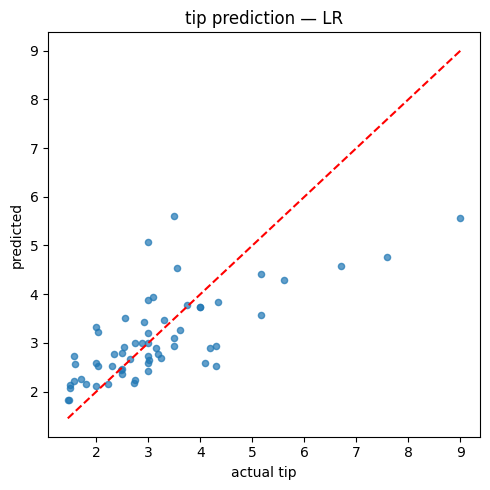

In [4]:
lr = LinearRegression(); lr.fit(X_train, y_train)
pred = lr.predict(X_test)

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, s=20, alpha=0.7)
lo, hi = y_test.min(), y_test.max()
plt.plot([lo, hi], [lo, hi], "r--")
plt.xlabel("actual tip"); plt.ylabel("predicted")
plt.title("tip prediction — LR")
plt.tight_layout(); plt.savefig(ART / "pred_vs_actual.png", dpi=120); plt.show()


## notes

Linear regression is roughly tied with RF here, which is what you'd expect since the relationship really is dominated by `total_bill` and the rest is small adjustments. R^2 lands around 0.45 — not great, but the floor on this dataset is high because tip behavior is genuinely noisy at the individual transaction level.

Tip percentage by day is actually flatter than I expected. The "weekend tippers tip more" stereotype isn't really visible in 244 rows.
